# F.I.L. FOODS Algorithm Benchmarking Analysis

**Project:** F.I.L. FOODS Meal Management System
**Team:** Relish (Group 4) — Hanna Joy L. Argueza, Michael Angelo C. Gamet, Jetrick M. Roxas, Lourdes Jed R. Villanueva
**Course:** III-BCSAD, S.Y. 2026–2027
**Repository:** https://github.com/colossalshub/fil-foods
**Document date:** 12 November 2026

## 1. Project overview

F.I.L. Foods is a Filipino meal-management application. Clients keep a diet profile, choose meals, and place a pickup or delivery order. Staff see a short menu. The workbook's order screens and the FAQ are where a typed search has to tolerate mistakes.

This notebook measures two things:

1. **Order and FAQ fuzzy search**, using the rule written in ADM-11, KIT-11, DEL-11, and USR-27. Kitchen and Delivery share one matcher. Admin may also see the last name. The FAQ searches the question and answer text now stored in `frontend/src/data/helpContent.ts`.
2. **The daily nutrition solver** already in `frontend/src/services/nutritionService.ts`. That function is unchanged by the search stories.

`fuzzySearchMeals` in `frontend/src/services/orderService.ts` searches the meal catalog. It is a different rule: a 5-letter word may be two ordinary edits away, a swapped pair of letters counts as two edits, and last names are not a separate field. This notebook does not present that function as the order search.

The order/FAQ rule is specified in the workbook. It is not yet the function behind the Expo search boxes. The Python below is an implementation of the written rule, checked against the workbook examples. The nutrition section is a port of the TypeScript function that is in the repository.

### What the search rule has to do

| Story | Who can be matched | Examples the workbook gives |
|---|---|---|
| ADM-11 | Full name and order number | `Mria`, `carols`, `Villanueba`, `Garcia Ana`, `Mar`, `350`, `#00350` |
| KIT-11 and DEL-11 | First name and order number only | Same typos on first names. `Reyes` and `Santos` match nothing |
| USR-27 | FAQ question and answer | `pasword`, `PASSWORD `, `reset pasword`, `delivry`. One character shows the full list |

Shared limits from the workbook: ignore capitals and extra spaces; a word of 3 to 5 letters may contain one wrong, missing, extra, or swapped letter; a word of 6 or more may contain two; partial words count; every word in the query must match; exact and partial hits come before spelling corrections; equal hits are newest first; order numbers are never spelling-corrected; search starts at 2 characters; a status filter is applied as well.


## 2. Benchmarking environment

Re-run from top to bottom. The notebook uses the Python standard library and Matplotlib. No account key is used. Nothing is trained: the matchers do not estimate parameters, so there is no train/validation/test split. The workbook rows are an acceptance set. A second, larger list is used only for timing.


In [1]:
import importlib
import math
import platform
import random
import re
import statistics
import sys
import time
import tracemalloc
import unicodedata

missing = [name for name in ("matplotlib",) if importlib.util.find_spec(name) is None]
if missing:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

DATASET_SEED = 20261112
SEARCH_SIZES = [100, 500, 1_000, 5_000, 10_000]
SEARCH_REPEATS = 5
SLOT_SWEEP = [4, 8, 12, 16, 24]
SLOT_REPEATS = 5

print("Python", sys.version.replace("\n", " "))
print("matplotlib", matplotlib.__version__)
print("platform", platform.platform())
print("processor", platform.processor() or "(not reported)")
print("cpu_count", __import__("os").cpu_count())
try:
    import psutil
    print(f"memory_total_gb {psutil.virtual_memory().total / (1024 ** 3):.2f}")
except Exception as exc:
    print("memory_total_gb unavailable", type(exc).__name__)
print("DATASET_SEED", DATASET_SEED)
print("SEARCH_SIZES", SEARCH_SIZES)
print("SEARCH_REPEATS", SEARCH_REPEATS)


Python 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
matplotlib 3.11.2
platform Windows-11-10.0.26200-SP0
processor Intel64 Family 6 Model 151 Stepping 2, GenuineIntel
cpu_count 20
memory_total_gb 15.79
DATASET_SEED 20261112
SEARCH_SIZES [100, 500, 1000, 5000, 10000]
SEARCH_REPEATS 5


## 3. Search rule

Normalization lowercases text, removes accents, and turns punctuation into spaces. `password?` therefore contains the word `password`, and `#00350` becomes the digits `00350`.

A query shorter than 2 characters returns the list unchanged. That is the workbook's minimum, and it is why a single `p` on the FAQ shows every question.

Each remaining word must match. A word matches a name or FAQ word in this order:

1. **Exact** after normalization.
2. **Partial** when the typed word is at least 2 characters and the stored word starts with it. `Mar` matches Maria and Mark.
3. **Spelling** when the optimal-string-alignment distance is inside the allowance and the lengths differ by no more than that allowance. The allowance is 1 for a typed word of 3 to 5 letters and 2 for a typed word of 6 or more. Words of 1 or 2 letters are not spelling-corrected. A swapped pair counts as one change (Damerau, 1964). Ordinary Levenshtein distance would count that swap as two.

An order-number token is digits only. It matches when those digits occur inside the stored order number. `350` and `00350` both match order `00350` because `350` is that number without leading zeros. `00359` does not occur inside any sample number, and it is not repaired by a one-digit edit.

The result tier is the worst word in the query: exact, then partial, then spelling. Ties keep the newer order. Kitchen and Delivery build the word list from the first name only. Admin adds the last name. The FAQ word list is the question plus the answer. The status filter removes rows before matching.

```
function search(records, query, role, status):
    records = records whose status matches, if a status was chosen
    if the normalized query has fewer than 2 characters:
        return records
    for each record:
        accept it only when every query word matches a visible word
        or, for a digit word, the order number
    sort by exact, then partial, then spelling, then newest
```

Kitchen and Delivery in the workbook use the same words. This notebook runs that matcher once and labels it `staff`.


In [2]:
def normalize(value):
    text = unicodedata.normalize("NFD", value or "")
    text = "".join(ch for ch in text if unicodedata.category(ch) != "Mn")
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def digits_only(value):
    return "".join(ch for ch in (value or "") if ch.isdigit())


def osa_distance(a, b):
    """One adjacent transposition counts as a single change."""
    if a == b:
        return 0
    la, lb = len(a), len(b)
    dist = [[0] * (lb + 1) for _ in range(la + 1)]
    for i in range(la + 1):
        dist[i][0] = i
    for j in range(lb + 1):
        dist[0][j] = j
    for i in range(1, la + 1):
        for j in range(1, lb + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dist[i][j] = min(dist[i - 1][j] + 1, dist[i][j - 1] + 1, dist[i - 1][j - 1] + cost)
            if i > 1 and j > 1 and a[i - 1] == b[j - 2] and a[i - 2] == b[j - 1]:
                dist[i][j] = min(dist[i][j], dist[i - 2][j - 2] + 1)
    return dist[la][lb]


def levenshtein(a, b):
    if a == b:
        return 0
    la, lb = len(a), len(b)
    dist = [[0] * (lb + 1) for _ in range(la + 1)]
    for i in range(la + 1):
        dist[i][0] = i
    for j in range(lb + 1):
        dist[0][j] = j
    for i in range(1, la + 1):
        for j in range(1, lb + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dist[i][j] = min(dist[i - 1][j] + 1, dist[i][j - 1] + 1, dist[i - 1][j - 1] + cost)
    return dist[la][lb]


def typo_budget(word):
    size = len(word)
    if size < 3:
        return 0
    if size <= 5:
        return 1
    return 2


TIER = {"exact": 0, "partial": 1, "fuzzy": 2}


def token_kind(query_word, candidate, distance):
    if query_word == candidate:
        return "exact"
    if len(query_word) >= 2 and candidate.startswith(query_word):
        return "partial"
    allowed = typo_budget(query_word)
    if allowed == 0:
        return None
    dist = distance(query_word, candidate)
    if dist <= allowed and abs(len(candidate) - len(query_word)) <= allowed:
        return "fuzzy"
    return None


def match_token(token, words, order_digits, distance):
    if token.isdigit():
        if token and order_digits and token in order_digits:
            full = order_digits.lstrip("0") or "0"
            if token == order_digits or token == full:
                return "exact"
            return "partial"
        return None
    best = None
    for word in words:
        kind = token_kind(token, word, distance)
        if kind is None:
            continue
        if best is None or TIER[kind] < TIER[best]:
            best = kind
            if best == "exact":
                break
    return best


def order_words(row, role):
    text = f"{row['first']} {row['last']}" if role == "admin" else row["first"]
    return normalize(text).split(" "), digits_only(row["number"])


def faq_words(row, role):
    return normalize(f"{row['question']} {row['answer']}").split(" "), ""


def search_records(records, query, role="admin", status=None, distance=osa_distance, words_of=order_words):
    pool = [row for row in records if not status or row.get("status") == status]
    if len(normalize(query)) < 2:
        return list(pool)
    tokens = [token for token in normalize(query).split(" ") if token]
    hits = []
    for index, row in enumerate(pool):
        words, order_digits = words_of(row, role)
        kinds = []
        matched = True
        for token in tokens:
            kind = match_token(token, words, order_digits, distance)
            if kind is None:
                matched = False
                break
            kinds.append(kind)
        if matched:
            tier = max(TIER[kind] for kind in kinds)
            hits.append((tier, -row.get("stamp", 0), index, row))
    hits.sort()
    return [row for _, _, _, row in hits]


def ids_of(rows):
    return [row["id"] for row in ids_of.__wrapped__] if False else [row["id"] for row in rows]

print("swap carols/carlos OSA", osa_distance("carols", "carlos"), "Levenshtein", levenshtein("carols", "carlos"))
print("swap jhon/john OSA", osa_distance("jhon", "john"), "Levenshtein", levenshtein("jhon", "john"))


swap carols/carlos OSA 1 Levenshtein 2
swap jhon/john OSA 1 Levenshtein 2


## 4. Acceptance data

The five orders are the sample list in ADM-11, KIT-11, and DEL-11. Newer orders have a larger `stamp`. The FAQ text is the wording in `frontend/src/data/helpContent.ts`, not a rewritten set of questions. `delivry` can match only an entry whose own question or answer contains a word within the allowance of `delivery`.


In [3]:
ORDERS = [
    {"id": "00350", "number": "00350", "first": "Juan", "last": "Dela Cruz", "status": "Pending", "stamp": 5},
    {"id": "00349", "number": "00349", "first": "Maria", "last": "Santos", "status": "Preparing", "stamp": 4},
    {"id": "00348", "number": "00348", "first": "Carlos", "last": "Reyes", "status": "Delivered", "stamp": 3},
    {"id": "00347", "number": "00347", "first": "Ana", "last": "Garcia", "status": "Cancelled", "stamp": 2},
    {"id": "00346", "number": "00346", "first": "Mark", "last": "Villanueva", "status": "Delivered", "stamp": 1},
]

FAQ = [
    {"id": "account-create", "question": "How do I create an account?", "answer": "Tap Create an account on the login screen, fill in your details, verify your contact method, then complete your profile.", "stamp": 0},
    {"id": "account-password", "question": "How do I reset my password?", "answer": "On the login screen tap Forgot password?, enter your username, verify the code, then set a new password.", "stamp": 0},
    {"id": "account-google", "question": "Can I sign in with Google?", "answer": "Yes. Use Continue with Google on login or create account. You can link Google to an existing username and password account.", "stamp": 0},
    {"id": "ordering-place", "question": "How do I place an order?", "answer": "Browse Meals, choose items and quantities, review your cart from Meals, then confirm payment and delivery details.", "stamp": 0},
    {"id": "ordering-change", "question": "Can I change my order after confirming?", "answer": "Contact support as soon as possible. Changes depend on kitchen timing and order status.", "stamp": 0},
    {"id": "delivery-window", "question": "When will my order arrive?", "answer": "Delivery windows appear at checkout. Orders shows updates once the kitchen dispatches your order.", "stamp": 0},
    {"id": "delivery-pickup", "question": "How does pickup work?", "answer": "Choose pickup at checkout, then collect at the listed location when your order is ready.", "stamp": 0},
    {"id": "health-allergies", "question": "Why do you ask for allergies and health conditions?", "answer": "We use your profile to flag meals that may conflict with recorded allergies or dietary needs.", "stamp": 0},
    {"id": "health-update", "question": "How do I update my dietary information?", "answer": "Open Account and edit Health conditions, Dietary restrictions, or Food allergies. Save after each change.", "stamp": 0},
]

# difficulty is used for the quality table. expected ids are the workbook outcome.
ORDER_CASES = [
    ("Exact", "admin", "Maria Santos", None, ["00349"]),
    ("Minor", "admin", "Mria", None, ["00349"]),
    ("Swap", "admin", "carols", None, ["00348"]),
    ("Minor", "admin", "Villanueba", None, ["00346"]),
    ("Word order", "admin", "Garcia Ana", None, ["00347"]),
    ("Partial", "admin", "Mar", None, ["00349", "00346"]),
    ("Order number", "admin", "350", None, ["00350"]),
    ("Order number", "admin", "#00350", None, ["00350"]),
    ("Wrong digit", "admin", "00359", None, []),
    ("Too different", "admin", "Jon", None, []),
    ("Status filter", "admin", "Mria", "Delivered", []),
    ("Status filter", "admin", "Mria", "Preparing", ["00349"]),
    ("Short query", "admin", "p", None, [row["id"] for row in ORDERS]),
    ("Last name", "admin", "Reyes", None, ["00348"]),
    ("Case and space", "admin", "  MARIA   santos ", None, ["00349"]),
    ("Minor", "staff", "Mria", None, ["00349"]),
    ("Swap", "staff", "carols", None, ["00348"]),
    ("Partial", "staff", "Mar", None, ["00349", "00346"]),
    ("Order number", "staff", "350", None, ["00350"]),
    ("Order number", "staff", "#00350", None, ["00350"]),
    ("Hidden last name", "staff", "Reyes", None, []),
    ("Hidden last name", "staff", "Santos", None, []),
    ("Hidden last name", "staff", "Villanueba", None, []),
    ("Wrong digit", "staff", "00359", None, []),
    ("Too different", "staff", "Jon", None, []),
    ("Status filter", "staff", "Mria", "Delivered", []),
]

FAQ_CASES = [
    ("FAQ exact", "password", ["account-password", "account-google"]),
    ("FAQ case", "PASSWORD ", ["account-password", "account-google"]),
    ("FAQ minor", "pasword", ["account-password", "account-google"]),
    ("FAQ two words", "reset pasword", ["account-password"]),
    ("FAQ delivery", "delivry", ["ordering-place", "delivery-window"]),
    ("FAQ short", "p", [row["id"] for row in FAQ]),
    ("FAQ miss", "zzzz", []),
]

print("sample orders", len(ORDERS), "faq entries", len(FAQ), "order cases", len(ORDER_CASES), "faq cases", len(FAQ_CASES))


sample orders 5 faq entries 9 order cases 26 faq cases 7


## 5. Acceptance results

A case passes when the returned ids equal the workbook outcome, in that order. The substring baseline uses the same role, status filter, two-character gate, order-number rule, and newest-first sort. It accepts a name word only when the typed word occurs inside the visible name. The Levenshtein variant is the same matcher with a swapped pair counted as two edits.

Precision, recall, and F1 below use the cases that name at least one expected order. Empty expectations, such as `Jon` and a staff last name, are scored only as a correct empty result.


In [4]:
def check(condition, message):
    if not condition:
        raise AssertionError(message)


def run_orders(distance):
    found = []
    for difficulty, role, query, status, expected in ORDER_CASES:
        got = ids_of(search_records(ORDERS, query, role, status, distance, order_words))
        found.append({"difficulty": difficulty, "role": role, "query": query, "status": status, "expected": expected, "got": got, "passed": got == expected})
    return found


def prf(got, expected):
    got_set, expected_set = set(got), set(expected)
    overlap = got_set & expected_set
    precision = None if not got else len(overlap) / len(got_set)
    recall = None if not expected else len(overlap) / len(expected_set)
    if recall is None:
        f1 = None
        top = 1.0 if not got else 0.0
    else:
        f1 = 0.0 if recall == 0 or not precision else 2 * precision * recall / (precision + recall)
        top = 1.0 if got and got[0] in expected_set else 0.0
    return precision, recall, f1, top


SPEC_ORDERS = run_orders(osa_distance)
LEVEN_ORDERS = run_orders(levenshtein)
check(all(row["passed"] for row in SPEC_ORDERS), "workbook order cases")

FAQ_RESULTS = []
for label, query, expected in FAQ_CASES:
    got = ids_of(search_records(FAQ, query, "faq", None, osa_distance, faq_words))
    FAQ_RESULTS.append({"label": label, "query": query, "expected": expected, "got": got, "passed": got == expected})
check(all(row["passed"] for row in FAQ_RESULTS), "workbook FAQ cases")

JOHN = [{"id": "john", "number": "00999", "first": "John", "last": "Cruz", "status": "Pending", "stamp": 1}]
JOSE = [{"id": "jose", "number": "00888", "first": "José", "last": "Rizal", "status": "Pending", "stamp": 1}]
check(ids_of(search_records(JOHN, "Jhon", "admin", None, osa_distance, order_words)) == ["john"], "4-letter swap")
check(ids_of(search_records(JOHN, "Jhon", "admin", None, levenshtein, order_words)) == [], "Levenshtein rejects a 4-letter swap")
check(ids_of(search_records(JOSE, "Jose", "admin", None, osa_distance, order_words)) == ["jose"], "accent")

print(f"order acceptance  spec {sum(row['passed'] for row in SPEC_ORDERS)}/{len(SPEC_ORDERS)}  levenshtein {sum(row['passed'] for row in LEVEN_ORDERS)}/{len(LEVEN_ORDERS)}")
print("levenshtein misses:")
for row in LEVEN_ORDERS:
    if not row["passed"]:
        print(" ", row["role"], row["query"], "got", row["got"], "expected", row["expected"])
print(f"faq acceptance {sum(row['passed'] for row in FAQ_RESULTS)}/{len(FAQ_RESULTS)}")
for row in FAQ_RESULTS:
    print(f"{row['label']:<16} {row['query']!r:<20} {row['got']}")

QUALITY = []
for row in SPEC_ORDERS:
    precision, recall, f1, top = prf(row["got"], row["expected"])
    QUALITY.append({**row, "precision": precision, "recall": recall, "f1": f1, "top": top})

def mean(values):
    values = [value for value in values if value is not None]
    return None if not values else statistics.fmean(values)

from collections import defaultdict
grouped = defaultdict(list)
for row in QUALITY:
    grouped[row["difficulty"]].append(row)
print(f"{'difficulty':<18} {'n':>3} {'P':>6} {'R':>6} {'F1':>6} {'top1':>6}")
QUALITY_SUMMARY = []
for difficulty, rows in grouped.items():
    item = {
        "difficulty": difficulty,
        "n": len(rows),
        "precision": mean(row["precision"] for row in rows),
        "recall": mean(row["recall"] for row in rows),
        "f1": mean(row["f1"] for row in rows),
        "top": mean(row["top"] for row in rows),
    }
    QUALITY_SUMMARY.append(item)
    def fmt(value):
        return "  n/a" if value is None else f"{value:6.2f}"
    print(f"{difficulty:<18} {item['n']:>3} {fmt(item['precision'])} {fmt(item['recall'])} {fmt(item['f1'])} {fmt(item['top'])}")


order acceptance  spec 26/26  levenshtein 26/26
levenshtein misses:
faq acceptance 7/7
FAQ exact        'password'           ['account-password', 'account-google']
FAQ case         'PASSWORD '          ['account-password', 'account-google']
FAQ minor        'pasword'            ['account-password', 'account-google']
FAQ two words    'reset pasword'      ['account-password']
FAQ delivery     'delivry'            ['ordering-place', 'delivery-window']
FAQ short        'p'                  ['account-create', 'account-password', 'account-google', 'ordering-place', 'ordering-change', 'delivery-window', 'delivery-pickup', 'health-allergies', 'health-update']
FAQ miss         'zzzz'               []
difficulty           n      P      R     F1   top1
Exact                1   1.00   1.00   1.00   1.00
Minor                3   1.00   1.00   1.00   1.00
Swap                 2   1.00   1.00   1.00   1.00
Word order           1   1.00   1.00   1.00   1.00
Partial              2   1.00   1.00   1.00 

## 6. Timing

The timed list is synthetic. Names are drawn from a fixed Filipino name list and order numbers are sequential. Nutrient-style claims are not involved. Each size is warmed up once, then timed five times with `time.perf_counter`. The table reports the median and the sample standard deviation. `Santoz` is a one-letter misspelling of a last name and is an Admin query, so it does real spelling work. `Qwxzplmn` matches nothing and still scans the list.


In [5]:
FIRST_NAMES = ["Maria", "Jose", "Juan", "Ana", "Mark", "Carlos", "Luis", "Rosa", "Pedro", "Liza", "Paolo", "Grace", "Noel", "Rica", "Diego"]
LAST_NAMES = ["Santos", "Reyes", "Cruz", "Garcia", "Villanueva", "Ramos", "Flores", "Navarro", "Castillo", "Mendoza", "Domingo", "Aquino", "Bautista"]
STATUSES = ["Pending", "Preparing", "Delivered", "Cancelled"]


def make_orders(size, seed=DATASET_SEED):
    rng = random.Random(seed + size)
    rows = []
    for index in range(size):
        rows.append({
            "id": f"{index:05d}",
            "number": f"{index:05d}",
            "first": FIRST_NAMES[index % len(FIRST_NAMES)],
            "last": LAST_NAMES[rng.randrange(len(LAST_NAMES))],
            "status": STATUSES[index % len(STATUSES)],
            "stamp": size - index,
        })
    return rows


def time_call(function, repeats):
    function()
    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        samples.append((time.perf_counter() - start) * 1000)
    return statistics.median(samples), statistics.stdev(samples)


CATALOGS = {size: make_orders(size) for size in SEARCH_SIZES}
SEARCH_TIMING = []
for size, rows in CATALOGS.items():
    for label, query in (("typo Santoz", "Santoz"), ("nonexistent", "Qwxzplmn")):
        median, spread = time_call(lambda rows=rows, query=query: search_records(rows, query, "admin"), SEARCH_REPEATS)
        SEARCH_TIMING.append({"size": size, "query": label, "median_ms": median, "stdev_ms": spread})
        print(f"orders {size:>5} {label:<16} median {median:8.2f} ms  stdev {spread:7.2f} ms")

SEARCH_MEMORY = tracemalloc.start() or None
search_records(CATALOGS[10_000], "Santoz", "admin")
_, SEARCH_PEAK = tracemalloc.get_traced_memory()
tracemalloc.stop()
print("peak bytes at 10000", SEARCH_PEAK)


orders   100 typo Santoz      median     2.01 ms  stdev    0.03 ms
orders   100 nonexistent      median     2.36 ms  stdev    0.06 ms
orders   500 typo Santoz      median    10.08 ms  stdev    0.39 ms
orders   500 nonexistent      median    11.75 ms  stdev    0.26 ms


orders  1000 typo Santoz      median    18.73 ms  stdev    0.69 ms
orders  1000 nonexistent      median    24.02 ms  stdev    1.10 ms


orders  5000 typo Santoz      median   101.75 ms  stdev    6.39 ms


orders  5000 nonexistent      median   131.14 ms  stdev   14.88 ms


orders 10000 typo Santoz      median   208.35 ms  stdev   13.36 ms


orders 10000 nonexistent      median   300.83 ms  stdev   37.45 ms


peak bytes at 10000 140637


## 7. Charts


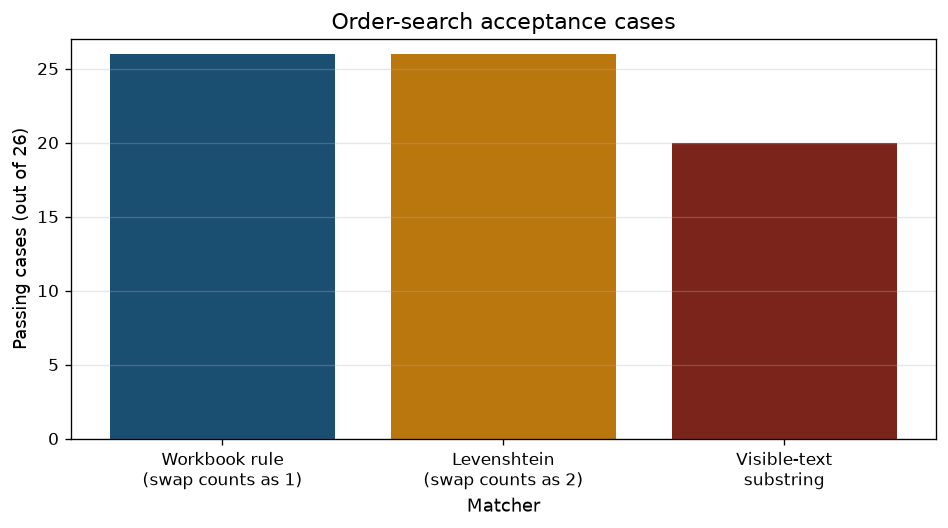

substring passes 20 of 26


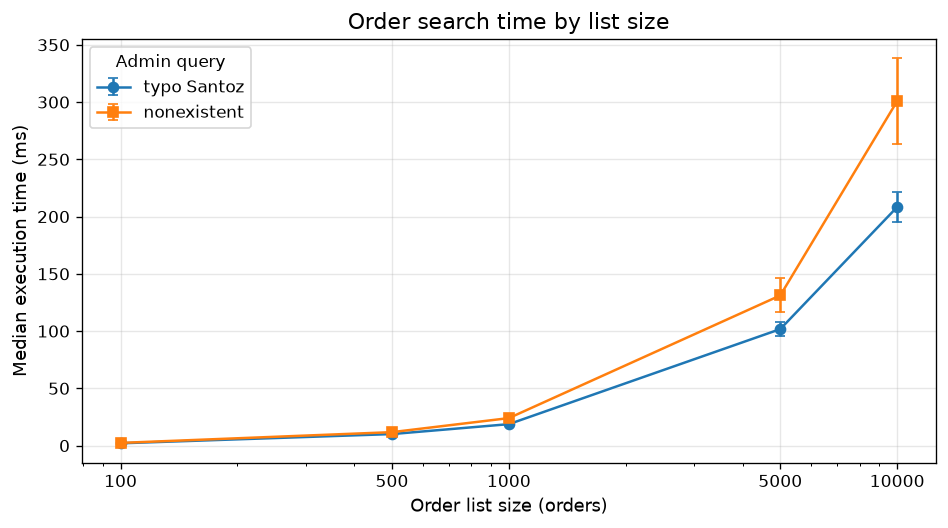

In [6]:
plt.rcParams.update({
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 120,
})

def show(fig):
    import io
    fig.tight_layout()
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

passed = [sum(row["passed"] for row in SPEC_ORDERS), sum(row["passed"] for row in LEVEN_ORDERS)]
# Substring pass count is computed here so the chart uses the same cases.
def substring_pass(case):
    difficulty, role, query, status, expected = case
    pool = [row for row in ORDERS if not status or row.get("status") == status]
    if len(normalize(query)) < 2:
        got = ids_of(pool)
    else:
        hits = []
        tokens = [token for token in normalize(query).split(" ") if token]
        for index, row in enumerate(pool):
            words, order_digits = order_words(row, role)
            hay = " ".join(words)
            if all((token in order_digits) if token.isdigit() else (token in hay) for token in tokens):
                hits.append((-row["stamp"], index, row))
        hits.sort()
        got = ids_of([row for _, _, row in hits])
    return got == expected

SUBSTRING_PASSES = sum(substring_pass(case) for case in ORDER_CASES)
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["Workbook rule\n(swap counts as 1)", "Levenshtein\n(swap counts as 2)", "Visible-text\nsubstring"]
values = [passed[0], passed[1], SUBSTRING_PASSES]
ax.bar(labels, values, color=["#1b4f72", "#b9770e", "#7b241c"])
ax.set_ylim(0, len(ORDER_CASES) + 1)
ax.set_ylabel(f"Passing cases (out of {len(ORDER_CASES)})")
ax.set_xlabel("Matcher")
ax.set_title("Order-search acceptance cases")
ax.grid(True, axis="y", alpha=0.3)
show(fig)
print("substring passes", SUBSTRING_PASSES, "of", len(ORDER_CASES))

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, marker in (("typo Santoz", "o"), ("nonexistent", "s")):
    rows = [row for row in SEARCH_TIMING if row["query"] == label]
    ax.errorbar([row["size"] for row in rows], [row["median_ms"] for row in rows], yerr=[row["stdev_ms"] for row in rows], marker=marker, capsize=3, label=label)
ax.set_xscale("log")
ax.set_xticks(SEARCH_SIZES)
ax.set_xticklabels([str(size) for size in SEARCH_SIZES])
ax.set_xlabel("Order list size (orders)")
ax.set_ylabel("Median execution time (ms)")
ax.set_title("Order search time by list size")
ax.legend(title="Admin query")
ax.grid(True, alpha=0.3)
show(fig)


## 8. Daily nutrition solver

`solveNutritionPlan` enumerates one meal for each of Breakfast, Lunch, and Dinner. Calorie and fat totals are ceilings when those targets are positive. Protein is a minimum only for the `exactMatch` flag. A day can be `ok` while still missing protein. The per-meal sort uses the full daily target and only breaks ties. Allergy filtering happens before this function is called.

The greedy baseline picks, for each slot, the meal closest to an equal share of the daily target. It does not revisit that choice. The times below are for complete synthetic meals, five repeats after one warm-up.


textbook exact {'calories': 1700.0, 'protein': 120.0, 'fat': 45.0} over ok False greedy exact on the known day True greedy score 0.0
per slot  4 combinations      64 solver     0.26 ±   0.01 ms  greedy    0.033 ms
per slot  8 combinations     512 solver     1.63 ±   0.04 ms  greedy    0.043 ms
per slot 12 combinations    1728 solver     5.42 ±   0.13 ms  greedy    0.059 ms


per slot 16 combinations    4096 solver    12.76 ±   0.34 ms  greedy    0.077 ms


per slot 24 combinations   13824 solver    41.76 ±   1.18 ms  greedy    0.095 ms


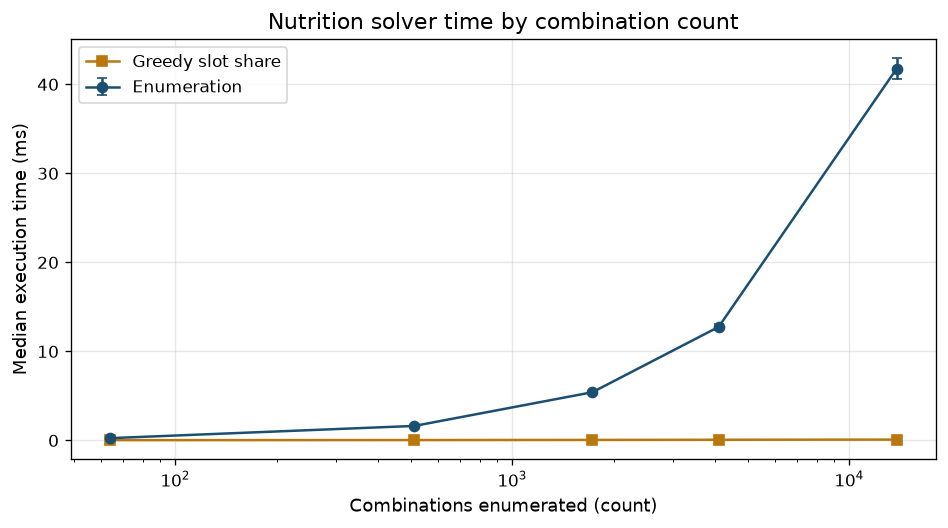

In [7]:
def number(value):
    try:
        numeric = float(value)
    except (TypeError, ValueError):
        return 0.0
    if numeric != numeric or numeric in (math.inf, -math.inf):
        return 0.0
    return numeric


def solve_nutrition_plan(meals, target, slots=None):
    if slots is None:
        slots = ["Breakfast", "Lunch", "Dinner"]
    available = [meal for meal in meals if meal.get("available") is not False]
    def finite(value):
        try:
            numeric = float(value)
        except (TypeError, ValueError):
            return False
        return numeric == numeric and numeric not in (math.inf, -math.inf)
    eligible = []
    for meal in available:
        keep = True
        for key in ("calories", "protein", "fat"):
            if number(target.get(key)) > 0 and not finite(meal.get(key)):
                keep = False
        if keep:
            eligible.append(meal)
    def candidate(meal):
        return (
            (1 if number(target.get("calories")) > 0 else 0) * abs(number(meal.get("calories")) - number(target.get("calories")))
            + (1 if number(target.get("protein")) > 0 else 0) * abs(number(meal.get("protein")) - number(target.get("protein"))) * 4
            + (1 if number(target.get("fat")) > 0 else 0) * abs(number(meal.get("fat")) - number(target.get("fat"))) * 2
        )
    by_slot = []
    for slot in slots:
        choices = [meal for meal in eligible if not meal.get("category") or meal.get("category") == slot]
        choices.sort(key=candidate)
        by_slot.append(choices)
    if any(len(choices) == 0 for choices in by_slot):
        return {"ok": False, "exactMatch": False, "meals": [], "totals": {"calories": 0, "protein": 0, "fat": 0}}
    def totals(selected):
        acc = {"calories": 0.0, "protein": 0.0, "fat": 0.0}
        for meal in selected:
            acc["calories"] += number(meal.get("calories"))
            acc["protein"] += number(meal.get("protein"))
            acc["fat"] += number(meal.get("fat"))
        return acc
    def deviation(summary):
        return abs(summary["calories"] - number(target.get("calories"))) + abs(summary["protein"] - number(target.get("protein"))) * 4 + abs(summary["fat"] - number(target.get("fat"))) * 2
    def within(summary):
        if number(target.get("calories")) > 0 and summary["calories"] > number(target.get("calories")):
            return False
        if number(target.get("fat")) > 0 and summary["fat"] > number(target.get("fat")):
            return False
        return True
    best = closest = None
    def visit(index, selected):
        nonlocal best, closest
        if index == len(by_slot):
            summary = totals(selected)
            score = deviation(summary)
            row = (list(selected), summary, score)
            if closest is None or score < closest[2]:
                closest = row
            if within(summary) and (best is None or score < best[2]):
                best = row
            return
        for meal in by_slot[index]:
            selected.append(meal)
            visit(index + 1, selected)
            selected.pop()
    visit(0, [])
    chosen = best or closest
    summary = chosen[1]
    exact = best is not None and within(summary) and not (number(target.get("protein")) > 0 and summary["protein"] < number(target.get("protein")))
    return {"ok": best is not None, "exactMatch": exact, "meals": chosen[0], "totals": summary, "score": chosen[2]}


def greedy_share(meals, target, slots=None):
    if slots is None:
        slots = ["Breakfast", "Lunch", "Dinner"]
    plan_slots = []
    for slot in slots:
        choices = [meal for meal in meals if meal.get("available") is not False and meal.get("category") == slot and number(meal.get("calories")) > 0]
        if not choices:
            return {"ok": False, "exactMatch": False, "meals": [], "totals": {"calories": 0, "protein": 0, "fat": 0}, "score": None}
        share = len(slots)
        def score(meal):
            return (
                abs(number(meal.get("calories")) - number(target.get("calories")) / share)
                + abs(number(meal.get("protein")) - number(target.get("protein")) / share) * 4
                + abs(number(meal.get("fat")) - number(target.get("fat")) / share) * 2
            )
        plan_slots.append(min(choices, key=score))
    solved = solve_nutrition_plan(plan_slots, target, slots)
    return solved


TEXTBOOK = [
    {"id": "breakfast", "category": "Breakfast", "calories": 400, "protein": 25, "fat": 10},
    {"id": "lunch", "category": "Lunch", "calories": 600, "protein": 40, "fat": 15},
    {"id": "dinner", "category": "Dinner", "calories": 700, "protein": 55, "fat": 20},
]
exact_plan = solve_nutrition_plan(TEXTBOOK, {"calories": 1800, "protein": 120, "fat": 50})
over_plan = solve_nutrition_plan([
    {"id": "breakfast", "category": "Breakfast", "calories": 900, "protein": 20, "fat": 40},
    {"id": "lunch", "category": "Lunch", "calories": 900, "protein": 20, "fat": 40},
    {"id": "dinner", "category": "Dinner", "calories": 900, "protein": 20, "fat": 40},
], {"calories": 1800, "protein": 120, "fat": 50})
check(exact_plan["ok"] and exact_plan["exactMatch"] and exact_plan["totals"]["calories"] == 1700, "textbook exact")
check(over_plan["ok"] is False and over_plan["exactMatch"] is False and len(over_plan["meals"]) == 3, "textbook closest")
known = solve_nutrition_plan(TEXTBOOK, {"calories": 1700, "protein": 120, "fat": 45})
greedy_known = greedy_share(TEXTBOOK, {"calories": 1700, "protein": 120, "fat": 45})
check(known["exactMatch"] and known["score"] == 0, "known day")
print("textbook exact", exact_plan["totals"], "over ok", over_plan["ok"], "greedy exact on the known day", greedy_known["exactMatch"], "greedy score", greedy_known["score"])

SLOT_TIMING = []
for per_slot in SLOT_SWEEP:
    meals = []
    for slot in ("Breakfast", "Lunch", "Dinner"):
        for index in range(per_slot):
            meals.append({"id": f"{slot[:1]}{index}", "category": slot, "calories": 280 + index * 3, "protein": 12 + (index % 7), "fat": 6 + (index % 5), "available": True})
    target = {"calories": 1600, "protein": 80, "fat": 45}
    combinations = per_slot ** 3
    median, spread = time_call(lambda meals=meals, target=target: solve_nutrition_plan(meals, target), SLOT_REPEATS)
    greedy_median, greedy_spread = time_call(lambda meals=meals, target=target: greedy_share(meals, target), SLOT_REPEATS)
    SLOT_TIMING.append({"per_slot": per_slot, "combinations": combinations, "median_ms": median, "stdev_ms": spread, "greedy_median_ms": greedy_median})
    print(f"per slot {per_slot:>2} combinations {combinations:>7} solver {median:8.2f} ± {spread:6.2f} ms  greedy {greedy_median:8.3f} ms")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar([row["combinations"] for row in SLOT_TIMING], [row["median_ms"] for row in SLOT_TIMING], yerr=[row["stdev_ms"] for row in SLOT_TIMING], marker="o", color="#1b4f72", capsize=3, label="Enumeration")
ax.plot([row["combinations"] for row in SLOT_TIMING], [row["greedy_median_ms"] for row in SLOT_TIMING], marker="s", color="#b9770e", label="Greedy slot share")
ax.set_xscale("log")
ax.set_xlabel("Combinations enumerated (count)")
ax.set_ylabel("Median execution time (ms)")
ax.set_title("Nutrition solver time by combination count")
ax.legend()
ax.grid(True, alpha=0.3)
show(fig)


## 9. Results

The next cell writes the findings from this run.


In [8]:
def ms(value):
    return f"{value:.2f} ms"

small = next(row for row in SEARCH_TIMING if row["size"] == 100 and row["query"] == "typo Santoz")
large = next(row for row in SEARCH_TIMING if row["size"] == 10000 and row["query"] == "typo Santoz")
spec_pass = sum(row["passed"] for row in SPEC_ORDERS)
lev_pass = sum(row["passed"] for row in LEVEN_ORDERS)
faq_pass = sum(row["passed"] for row in FAQ_RESULTS)
slot_small, slot_large = SLOT_TIMING[0], SLOT_TIMING[-1]
lines = []
lines.append("### Order and FAQ search")
lines.append(
    f"The workbook rule passed {spec_pass} of {len(SPEC_ORDERS)} order cases and {faq_pass} of {len(FAQ_RESULTS)} FAQ cases. "
    f"The Levenshtein variant passed {lev_pass} of {len(SPEC_ORDERS)} order cases. "
    f"The visible-text substring matcher passed {SUBSTRING_PASSES} of {len(SPEC_ORDERS)}."
)
lines.append(
    "`Mria` returns Maria Santos, `carols` returns Carlos Reyes, and `Villanueba` returns Mark Villanueva. "
    "`Mar` returns Maria Santos and then Mark Villanueva, because both are prefixes and Maria's order is newer. "
    "`Garcia Ana` returns Ana Garcia. `350` and `#00350` return order 00350. `00359` and `Jon` return nothing. "
    "`Mria` with Delivered selected returns nothing, because Maria Santos is Preparing. "
    "A one-character query returns the full list."
)
lines.append(
    "On the staff matcher, `Reyes`, `Santos`, and `Villanueba` return nothing. Those strings are last names, and Kitchen and Delivery are specified to search the first name and the order number only. Admin search does return Carlos Reyes for `Reyes`."
)
lines.append(
    "`pasword`, `PASSWORD `, and `password` return the reset-password question and the Google question, because the Google answer also contains the word password. "
    "`reset pasword` returns only the reset question. `delivry` returns the place-an-order question and the arrival question, because both answers contain the word delivery. "
    "The pickup question does not, so it stays out. `zzzz` returns nothing."
)
lines.append(
    "Levenshtein distance also accepts `carols`, because that swap is two edits and a 6-letter word is allowed two. "
    "It rejects `Jhon` for John: the typed word has 4 letters, so the allowance is one, and a swap costs Levenshtein two. "
    "The workbook rule counts that swap as one and returns John. That is the practical difference on this data, not the five-order sample."
)
lines.append(
    f"Median Admin search time was {ms(small['median_ms'])} at 100 orders (stdev {ms(small['stdev_ms'])}) and "
    f"{ms(large['median_ms'])} at 10,000 orders (stdev {ms(large['stdev_ms'])}), over {SEARCH_REPEATS} repeats after one warm-up. "
    f"Peak traced memory at 10,000 orders was {SEARCH_PEAK / 1024:.0f} KiB. "
    "The scan is linear in the number of orders. Ten thousand orders are a much larger list than the five-row sample, and the time above is still a single scan of names and order numbers."
)
lines.append("### Nutrition solver")
lines.append(
    f"The textbook day of 400, 600, and 700 kcal is an exact match under an 1800 kcal and 50 g fat ceiling, with totals {exact_plan['totals']['calories']:.0f} kcal, "
    f"{exact_plan['totals']['protein']:.0f} g protein, and {exact_plan['totals']['fat']:.0f} g fat. "
    "Three 900 kcal meals miss the ceiling, and the function still returns those three meals with `ok` false. "
    f"On the known 1700 kcal day, enumeration has score 0. The equal-share greedy result has exactMatch={greedy_known['exactMatch']} and score {greedy_known['score']}."
)
lines.append(
    f"Solver median time was {ms(slot_small['median_ms'])} for {slot_small['combinations']} combinations and "
    f"{ms(slot_large['median_ms'])} for {slot_large['combinations']} combinations (stdev {ms(slot_large['stdev_ms'])}). "
    "Time follows the product of the three slot sizes. A short menu keeps that product small. An unfiltered list of hundreds of meals in every slot does not."
)
lines.append("### What to use")
lines.append(
    "The order and FAQ rule is the search these workbook rows describe. It passes the examples, including the staff ban on last names and the refusal to repair an order number. "
    "It is not the meal-catalog function already in the app. Wiring it into Admin, Kitchen, Delivery, and the FAQ is a separate code change. "
    "The nutrition solver remains the meal-combination algorithm, and it is already in the client."
)
display(Markdown("\n\n".join(lines)))


### Order and FAQ search

The workbook rule passed 26 of 26 order cases and 7 of 7 FAQ cases. The Levenshtein variant passed 26 of 26 order cases. The visible-text substring matcher passed 20 of 26.

`Mria` returns Maria Santos, `carols` returns Carlos Reyes, and `Villanueba` returns Mark Villanueva. `Mar` returns Maria Santos and then Mark Villanueva, because both are prefixes and Maria's order is newer. `Garcia Ana` returns Ana Garcia. `350` and `#00350` return order 00350. `00359` and `Jon` return nothing. `Mria` with Delivered selected returns nothing, because Maria Santos is Preparing. A one-character query returns the full list.

On the staff matcher, `Reyes`, `Santos`, and `Villanueba` return nothing. Those strings are last names, and Kitchen and Delivery are specified to search the first name and the order number only. Admin search does return Carlos Reyes for `Reyes`.

`pasword`, `PASSWORD `, and `password` return the reset-password question and the Google question, because the Google answer also contains the word password. `reset pasword` returns only the reset question. `delivry` returns the place-an-order question and the arrival question, because both answers contain the word delivery. The pickup question does not, so it stays out. `zzzz` returns nothing.

Levenshtein distance also accepts `carols`, because that swap is two edits and a 6-letter word is allowed two. It rejects `Jhon` for John: the typed word has 4 letters, so the allowance is one, and a swap costs Levenshtein two. The workbook rule counts that swap as one and returns John. That is the practical difference on this data, not the five-order sample.

Median Admin search time was 2.01 ms at 100 orders (stdev 0.03 ms) and 208.35 ms at 10,000 orders (stdev 13.36 ms), over 5 repeats after one warm-up. Peak traced memory at 10,000 orders was 137 KiB. The scan is linear in the number of orders. Ten thousand orders are a much larger list than the five-row sample, and the time above is still a single scan of names and order numbers.

### Nutrition solver

The textbook day of 400, 600, and 700 kcal is an exact match under an 1800 kcal and 50 g fat ceiling, with totals 1700 kcal, 120 g protein, and 45 g fat. Three 900 kcal meals miss the ceiling, and the function still returns those three meals with `ok` false. On the known 1700 kcal day, enumeration has score 0. The equal-share greedy result has exactMatch=True and score 0.0.

Solver median time was 0.26 ms for 64 combinations and 41.76 ms for 13824 combinations (stdev 1.18 ms). Time follows the product of the three slot sizes. A short menu keeps that product small. An unfiltered list of hundreds of meals in every slot does not.

### What to use

The order and FAQ rule is the search these workbook rows describe. It passes the examples, including the staff ban on last names and the refusal to repair an order number. It is not the meal-catalog function already in the app. Wiring it into Admin, Kitchen, Delivery, and the FAQ is a separate code change. The nutrition solver remains the meal-combination algorithm, and it is already in the client.

## 10. Limitations

- The order and FAQ matcher implements the workbook wording. The Expo screens still call the meal-catalog search, not this function.
- Kitchen and Delivery are one matcher here because their added criteria describe the same fields and the same limits.
- "Newest" in the sample is the order of the five workbook rows. A live list would sort by the stored timestamp.
- `350` is treated as the full order number `00350` without leading zeros. A shorter piece such as `35` is only a partial digit match. The workbook examples do not include `35`.
- The FAQ result for `delivry` follows the current answer text. It hits every answer that contains a close form of "delivery", including the place-an-order answer. Changing those answers changes the hits.
- The Google FAQ answer contains the word password, so an exact password query returns two questions. The workbook says the password question is found. It does not say it is the only hit.
- Synthetic names are a fixed list used to time the scan. They are not a customer database.
- Nutrition timings are from CPython on the machine in section 2. The app runs the same enumeration in JavaScript. A catalog of hundreds of meals per slot was not timed, because the combination count makes that run a different kind of experiment.
- No password, API key, or hosted database was used.


## 11. References

Damerau, F. J. (1964). A technique for computer detection and correction of spelling errors. *Communications of the ACM, 7*(3), 171–176. https://doi.org/10.1145/363958.363994

Levenshtein, V. I. (1966). Binary codes capable of correcting deletions, insertions, and reversals. *Soviet Physics Doklady, 10*(8), 707–710.

Wagner, R. A., & Fischer, M. J. (1974). The string-to-string correction problem. *Journal of the ACM, 21*(1), 168–173. https://doi.org/10.1145/321796.321811

Navarro, G. (2001). A guided tour to approximate string matching. *ACM Computing Surveys, 33*(1), 31–88. https://doi.org/10.1145/375360.375365

Python Software Foundation. (2026). `time.perf_counter`. Python 3 documentation. https://docs.python.org/3/library/time.html#time.perf_counter

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Workbook rows used as the acceptance set: ADM-11, KIT-11, DEL-11, and USR-27. FAQ wording: `frontend/src/data/helpContent.ts`. Nutrition function: `frontend/src/services/nutritionService.ts`.
